In [309]:
import torch
from torch import nn
import matplotlib.pyplot as plt
import numpy as np

In [310]:
weight=0.7
bais=0.3

X=torch.arange(0,1,0.02)
y=weight*X+bais

In [311]:
len(X),len(y)

(50, 50)

In [312]:
train_split=int(0.8*len(X))
X_train,y_train=X[:train_split],y[:train_split]
X_test,y_test=X[train_split:],y[train_split:]

len(X_train),len(y_train),len(X_test),len(y_test)

(40, 40, 10, 10)

In [313]:
class LinearRegression(nn.Module):
    def __init__(self):
        super().__init__()
        self.weights=nn.Parameter(torch.randn(1,requires_grad=True,dtype=float))
        self.bais=nn.Parameter(torch.randn(1,requires_grad=True,dtype=float))
    def forward(self,x:torch.Tensor)->torch.Tensor:
        return self.weights*x+self.bais


In [314]:
torch.manual_seed(42)
model=LinearRegression()
list(model.parameters())

[Parameter containing:
 tensor([0.3367], dtype=torch.float64, requires_grad=True),
 Parameter containing:
 tensor([0.1288], dtype=torch.float64, requires_grad=True)]

In [315]:
model.state_dict()

OrderedDict([('weights', tensor([0.3367], dtype=torch.float64)),
             ('bais', tensor([0.1288], dtype=torch.float64))])

In [316]:
with torch.inference_mode():
    y_pred=model(X_test)
y_pred

tensor([0.3982, 0.4049, 0.4116, 0.4184, 0.4251, 0.4318, 0.4386, 0.4453, 0.4520,
        0.4588], dtype=torch.float64)

In [317]:
y_test

tensor([0.8600, 0.8740, 0.8880, 0.9020, 0.9160, 0.9300, 0.9440, 0.9580, 0.9720,
        0.9860])

In [318]:
def plot_prediction(train_data=X_train,train_labels=y_train,test_data=X_test,test_labels=y_test,predictions=None):
    plt.figure(figsize=(10,5))

    plt.scatter(train_data,train_labels,c="b",s=4,label="Training data")
    plt.scatter(test_data,test_labels,c="g",s=4,label="Testing data")

    if predictions is not None:
        plt.scatter(test_data,predictions,c="r",s=4,label="Predictions")
    plt.legend(prop={"size":14});
    plt.show()

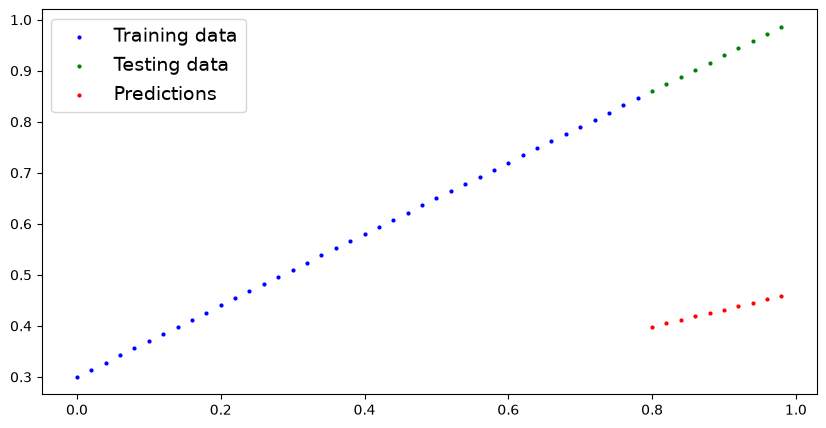

In [319]:
plot_prediction(predictions=y_pred)

In [320]:
list(model.parameters())

[Parameter containing:
 tensor([0.3367], dtype=torch.float64, requires_grad=True),
 Parameter containing:
 tensor([0.1288], dtype=torch.float64, requires_grad=True)]

In [321]:
loss_f=nn.L1Loss()
optimizer=torch.optim.SGD(params=model.parameters(),lr=0.01)

In [322]:
torch.manual_seed(42)
epocs=200

epoc_counts=[]
loss_values=[]
test_loss_values=[]

for epoc in range(epocs):

    model.train()

    y_pred=model(X_train)

    loss=loss_f(y_pred,y_train)

    print(f"Loss: {loss}")

    optimizer.zero_grad()

    loss.backward()

    optimizer.step()

    model.eval()

    with torch.inference_mode():
        test_pred=model(X_test)
        test_loss=loss_f(test_pred,y_test)
    if epoc%10==0:
        epoc_counts.append(epoc)
        loss_values.append(loss)
        test_loss_values.append(test_loss)

        print("-"*20)
        print(f"Epoc:{epoc} | Loss:{loss} | Test loss:{test_loss}")
        print(model.state_dict())
        print("-"*20)
    

Loss: 0.31288135683755547
--------------------
Epoc:0 | Loss:0.31288135683755547 | Test loss:0.4810651841540759
OrderedDict({'weights': tensor([0.3406], dtype=torch.float64), 'bais': tensor([0.1388], dtype=torch.float64)})
--------------------
Loss: 0.30136035690119084
Loss: 0.2898393569648262
Loss: 0.27831835702846164
Loss: 0.266797357092097
Loss: 0.2552763571557324
Loss: 0.24375535721936775
Loss: 0.23223435728300315
Loss: 0.22071335734663852
Loss: 0.20919235741027392
Loss: 0.1976713574739093
--------------------
Epoc:10 | Loss:0.1976713574739093 | Test loss:0.346355184508239
OrderedDict({'weights': tensor([0.3796], dtype=torch.float64), 'bais': tensor([0.2388], dtype=torch.float64)})
--------------------
Loss: 0.18615035753754472
Loss: 0.1746293576011801
Loss: 0.16310835766481552
Loss: 0.15158735772845094
Loss: 0.14006635779208632
Loss: 0.1285453578557217
Loss: 0.11702435791935709
Loss: 0.1060911877199048
Loss: 0.09681281918065873
Loss: 0.08908721056311557
--------------------
Epoc:2

In [323]:
np.array(torch.tensor(loss_values).cpu().numpy()),test_loss_values

(array([0.31288136, 0.19767136, 0.08908721, 0.0531485 , 0.04543793,
        0.04167861, 0.03818929, 0.03476085, 0.03132381, 0.02788737,
        0.02445893, 0.02102021, 0.01758544, 0.01415541, 0.01071661,
        0.00728351, 0.00385181, 0.00893124, 0.00893124, 0.00893124]),
 [tensor(0.4811, dtype=torch.float64),
  tensor(0.3464, dtype=torch.float64),
  tensor(0.2173, dtype=torch.float64),
  tensor(0.1446, dtype=torch.float64),
  tensor(0.1136, dtype=torch.float64),
  tensor(0.0992, dtype=torch.float64),
  tensor(0.0889, dtype=torch.float64),
  tensor(0.0806, dtype=torch.float64),
  tensor(0.0723, dtype=torch.float64),
  tensor(0.0647, dtype=torch.float64),
  tensor(0.0565, dtype=torch.float64),
  tensor(0.0482, dtype=torch.float64),
  tensor(0.0406, dtype=torch.float64),
  tensor(0.0323, dtype=torch.float64),
  tensor(0.0241, dtype=torch.float64),
  tensor(0.0165, dtype=torch.float64),
  tensor(0.0082, dtype=torch.float64),
  tensor(0.0050, dtype=torch.float64),
  tensor(0.0050, dtype=t

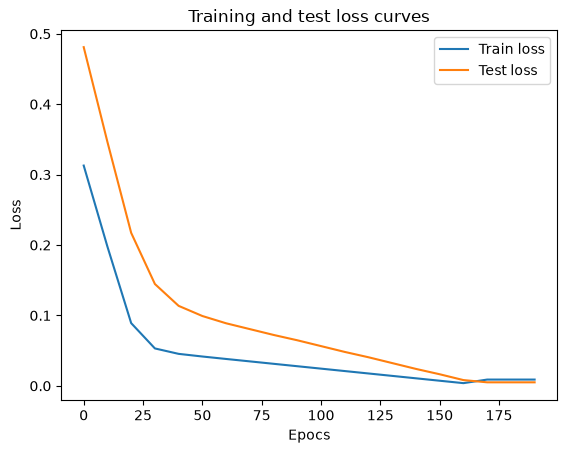

In [324]:
plt.plot(epoc_counts,np.array(torch.tensor(loss_values).numpy()),label="Train loss")
plt.plot(epoc_counts,test_loss_values,label="Test loss")
plt.title("Training and test loss curves")
plt.ylabel("Loss")
plt.xlabel("Epocs")
plt.legend()
plt.show()

In [325]:
with torch.inference_mode():
    y_pred_new=model(X_test)

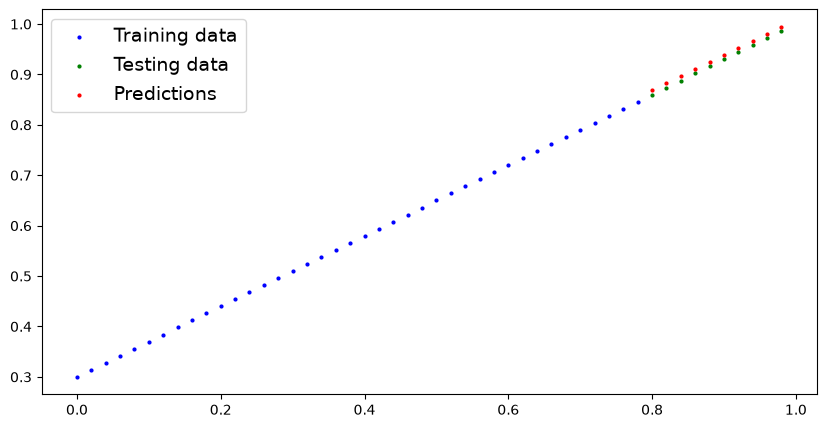

In [326]:
plot_prediction(predictions=y_pred_new)

In [332]:
from pathlib import Path

MODEL_PATH=Path("models")
MODEL_PATH.mkdir(parents=True,exist_ok=True)

MODEL_NAME="O1_pytorch_workflow_model_0.pth"
MODEL_SAVE_PATH=MODEL_PATH/MODEL_NAME

print(f"Saving model to:{MODEL_SAVE_PATH}")

torch.save(obj=model.state_dict(),f=MODEL_SAVE_PATH)

Saving model to:models/O1_pytorch_workflow_model_0.pth


In [328]:
model

LinearRegression()

In [333]:
!ls -1 models

O1_pytorch_workflow_model_0.pth


In [336]:
loaded_model=LinearRegression()

loaded_model.load_state_dict(torch.load(f=MODEL_SAVE_PATH))

<All keys matched successfully>

In [337]:
loaded_model.state_dict()

OrderedDict([('weights', tensor([0.6990], dtype=torch.float64)),
             ('bais', tensor([0.3093], dtype=torch.float64))])

In [339]:
loaded_model.eval()

with torch.inference_mode():
    loaded_model_preds=model(X_test)

loaded_model_preds

tensor([0.8685, 0.8825, 0.8965, 0.9105, 0.9245, 0.9384, 0.9524, 0.9664, 0.9804,
        0.9944], dtype=torch.float64)

In [342]:
y_pred_new==loaded_model_preds

tensor([True, True, True, True, True, True, True, True, True, True])